# **Global Solution 2026.2 - HelmCare: risco de sinistros graves com motocicletas em São Paulo**

Professor Danilo Rodrigues de Assis Elias - Inteligência Artificial e Machine Learning

---

### **Integrante (3ESPW):**

- Renan Dias Utida - RM 558540

---

### **Informações do Projeto:**

- **Desafio:** Global Solution 2026.2, tema CitizenTech (Engenharia de Software, 3º ano, FIAP Paulista)
- **CitizenTech:** HelmCare, *"Do risco ao resgate, cuidado em cada corrida."*
- **Cidadão beneficiado:** motociclistas que trabalham com entregas por aplicativo na cidade de São Paulo
- **Papel desta parte:** o modelo alimenta o componente `sinistro` (50%) do Índice de Risco do Turno, calculado pelo Serviço de Risco
- **Repositório:** https://github.com/renan-utida/helmcare (pasta `ml/`)
- **Entrega:** 19/11/2026

### **Objetivo:**

Transformar o problema do HelmCare em uma pergunta de Machine Learning e respondê-la com dados reais e públicos: estimar quantos sinistros graves com motocicletas são esperados em cada hora na cidade de São Paulo, dados o calendário e as condições do tempo. O notebook percorre o ciclo completo (preparação dos dados, treino com diferentes hiperparâmetros e avaliação em treino e teste) e termina traduzindo o resultado para o entregador.

# **Descrição do Desafio**

### **Inteligência Artificial & Machine Learning · Global Solution 2026.2 (CitizenTech)**

#### **Conceito da atividade.** Transformar o problema da CitizenTech em uma pergunta de Machine Learning e respondê-la com dados reais e públicos sobre a cidade: INMET, Metrô SP, Infosiga SP, SP156, IBGE, entre outros.

#### **Objetivo.** Percorrer o ciclo completo de ML: preparar os dados, treinar um modelo (XGBoost, Random Forest, MLP, LSTM ou KMeans + PCA) com diferentes hiperparâmetros, avaliá-lo em treino e teste e concluir o que o resultado significa para o cidadão.

#### **O percurso**

| Etapa | O que fazer |
|---|---|
| 01. Problema e dados reais | Escolher o problema da CitizenTech, transformá-lo em uma pergunta de ML e pesquisar dados reais e públicos. Documentar fonte, link e período. |
| 02. Modelo e preparação | Escolher um modelo: XGBoost, Random Forest, MLP, LSTM ou KMeans (+PCA). Limpar os dados e dividir em treino e teste. |
| 03. Treino e avaliação | Testar ao menos 10 combinações de 3 hiperparâmetros, com validação cruzada só no treino, e avaliar com métricas adequadas. |
| 04. Resultados e conclusão | Mostrar as métricas de treino e teste lado a lado, com gráficos, e discutir overfitting. Concluir o que o resultado significa para o cidadão. |

#### **Entregáveis**

- Repositório GitHub: pasta `ml/` com o notebook executado, `dados/README.md` e `requirements.txt`.
- Relatório `RELATORIO_ML.md`, do problema à conclusão (o enunciado indica de 2 a 4 páginas, e o quadro de critérios cita 2 páginas).
- Vídeo de até 5 minutos no YouTube (não listado).

Um integrante envia no Teams os links do repositório e do vídeo até 19/11, às 23h55. **Dados simulados não são aceitos.**

#### **Pontuação (10,0)**

| Critério | Pontos |
|---|---|
| Problema e dados reais | 2,0 |
| Escolha justificada do modelo | 1,0 |
| Preparação e divisão treino/teste | 2,0 |
| Treino com diferentes parâmetros | 2,0 |
| Resultados em treino e teste | 2,0 |
| Conclusão e leitura para o cidadão | 1,0 |

# **Solução Proposta**

O HelmCare atua em três momentos da vida do entregador: **prevenir** (antes do turno), **socorrer** (durante a queda) e **proteger** (depois dela). Este notebook constrói a parte da prevenção que depende de dados: o componente `sinistro` do **Índice de Risco do Turno**.

| Componente do índice | Peso | Fonte |
|---|---|---|
| `sinistro`: sinistros graves esperados nas horas do turno | 50% | **Modelo deste notebook** (Infosiga + INMET) |
| `chuva`: chuva prevista no turno | 25% | Previsão do tempo |
| `calor`: índice de calor | 25% | Previsão do tempo + sensor DHT22 do capacete |

O modelo é treinado aqui e exportado para a pasta `ml/modelo/`. De lá, o Serviço de Risco (FastAPI, disciplina de SOA) o carrega para responder ao `POST /indice-turno` (Contrato de Integração v1.1, seção 8.1).

### **Pergunta de Machine Learning**

> Quantos sinistros graves com motocicletas são esperados na cidade de São Paulo em cada hora local (0 a 23), dados o calendário (hora, dia da semana, mês e feriado) e as condições do tempo naquela hora (chuva, temperatura e umidade)?

### **Dados reais e públicos**

| Dado | Fonte | Link | Período usado | Uso no projeto |
|---|---|---|---|---|
| Sinistros de trânsito: sinistros, pessoas (vítimas) e veículos (versão 3.1, atualizada em 19/10/2026) | Infosiga SP (Detran-SP), licença CC BY 4.0 | https://infosiga.detran.sp.gov.br/ | 2019 a 2025 | Variável-alvo e trechos críticos |
| Dados meteorológicos horários da estação automática A701 (São Paulo, Mirante de Santana) | INMET (Instituto Nacional de Meteorologia) | https://portal.inmet.gov.br/dadoshistoricos | 2019 a 2025 | Chuva, temperatura e umidade |

Os dados foram baixados em 07/11/2026. O período começa em 2019 porque só a partir desse ano o Infosiga registra também os sinistros não fatais, e termina em 2025 porque 2026 ainda está incompleto. O passo a passo do download e os tratamentos aplicados estão em `dados/README.md`.

### **Roteiro**

- **Item 0:** Configuração do ambiente e reprodutibilidade
- **Item 1:** Infosiga: leitura e funil de filtros
- **Item 2:** Definição de sinistro grave e da variável-alvo
- **Item 3:** INMET: leitura, faltantes e conversão de fuso
- **Item 4:** Base horária: grade completa de horas, calendário, feriados e junção com o tempo
- **Item 5:** Análise exploratória
- **Item 6:** Escolha justificada do modelo, variáveis e divisão treino/teste
- **Item 7:** Linhas de base
- **Item 8:** Treino com diferentes hiperparâmetros (validação cruzada só no treino)
- **Item 9:** Resultados em treino e teste, overfitting e efeito do tempo
- **Item 10:** Exportação dos artefatos para o Serviço de Risco
- **Item 11:** Conclusão e leitura para o entregador
- **Item 12:** Cobertura da rubrica e dos entregáveis

## **Introdução: problema, pergunta e hipótese**

### **Problema**

Em 2025, a cidade de São Paulo registrou 1.034 mortes no trânsito, o maior número desde 2015, e os motociclistas foram o maior grupo de vítimas, com 475 mortes. Entre janeiro e agosto de 2026, motos estiveram envolvidas em 67,3% dos sinistros graves ou fatais da cidade (dados do Infosiga SP divulgados pela imprensa; fontes no Item 12). O Item 2 confere o número de motociclistas mortos em 2025 com os dados deste notebook.

Por trás desses números está o entregador de aplicativo, que passa o turno inteiro exposto ao trânsito, à chuva e ao calor, sem nenhuma informação sobre o risco do horário em que vai trabalhar.

### **Pergunta**

Quantos sinistros graves com motocicletas são esperados na cidade de São Paulo em cada hora local (0 a 23), dados o calendário e as condições do tempo naquela hora? A "faixa horária" da Ficha da CitizenTech corresponde, aqui, a uma hora local.

### **Tipo de problema**

Regressão de contagem. O alvo é um número inteiro, não negativo e pequeno em cada hora, porque sinistros graves são raros quando olhados hora a hora. Para o índice, o que interessa é a **quantidade esperada** em cada hora, e não acertar o número exato de uma hora específica.

### **Hipótese inicial.**

- **H1 (horário):** a quantidade esperada de sinistros graves varia muito ao longo do dia. É maior nos horários de mais circulação e de entregas e menor de madrugada.
- **H2 (chuva):** na mesma hora e no mesmo dia da semana, horas com chuva têm mais sinistros graves do que horas secas.
- **H3 (temperatura e umidade):** têm efeito menor que o da chuva.
- **H4 (tamanho do ganho):** medido hora a hora, o tempo acrescenta pouco ao que o calendário já explica, porque cada hora tem poucos casos e muito acaso. O efeito deve aparecer melhor em médias.

Os resultados testam essas hipóteses, e a conclusão (Item 11) diz o que foi confirmado e o que não foi.

### **Limite conhecido desde o início**

A quantidade de sinistros também reflete quantas motos estão circulando (exposição). Os dados públicos não trazem esse volume por hora, então o modelo mede quando os sinistros graves acontecem, e não o perigo de cada viagem. Esse limite volta na conclusão.

### **Protocolo experimental**

As regras abaixo foram definidas antes de olhar os resultados e valem para todo o notebook.

| Escolha | Decisão | Justificativa |
|---|---|---|
| Unidade de análise | Uma hora local (0 a 23) de um dia, na cidade inteira | É o que o Serviço de Risco consulta (Contrato v1.1, seção 8.1) e a menor granularidade do INMET |
| Variável-alvo | Quantidade de sinistros graves com motocicleta na hora. Proposta: sinistro com pelo menos uma moto e pelo menos uma vítima com lesão grave ou fatal. Decisão final no Item 2 | Critério "graves ou fatais" das estatísticas de segurança viária. **Regra prévia:** se em menos de 80% desses sinistros a vítima grave ou fatal estiver na moto, o alvo passa a ser "sinistros com vítima grave ou fatal na moto", que é o risco do entregador |
| Período e local | 2019 a 2025, município de São Paulo (IBGE 3550308) | Sinistros não fatais só a partir de 2019; 2026 está incompleto |
| Horas sem sinistro | Entram com alvo 0 (grade completa de 61.368 horas) | Sem elas, o modelo nunca vê o "nada aconteceu" e superestima o risco |
| Fuso horário | INMET convertido de UTC para `America/Sao_Paulo` | Até 16/02/2019 ainda havia horário de verão (UTC-2); uma conversão fixa de 3 horas erraria esse período |
| Horas sem dados do tempo | Excluídas do treino e do teste, com a quantidade registrada (confirmado no Item 4) | Inventar a chuva de uma hora atrapalharia justamente o efeito que o modelo precisa aprender |
| Variáveis de entrada | Hora, dia da semana, mês, feriado, chuva (mm/h), temperatura (°C) e umidade (%) | Somente o que o Serviço de Risco monta a partir do `POST /indice-turno` (Contrato v1.1). Códigos inteiros, porque árvores não precisam de one-hot nem de padronização |
| Ano | Fora do modelo. Usado só na análise exploratória e no diagnóstico do teste | Não consta das entradas do Contrato; árvores não extrapolam (em 2026, o modelo trataria tudo como o último ano visto); e a tendência anual mistura mudança de risco com mudança de registro. O possível viés de nível em 2025 é medido no Item 9 |
| Feriados | Nacionais e estaduais de SP (biblioteca `holidays`) e municipais da capital (25/01, Corpus Christi e 20/11). Regra final, incluindo o Carnaval, no Item 4 | A regra e a lista explícita de datas vão para o `metadados_modelo.json`, para o Serviço de Risco reproduzir exatamente |
| Divisão treino e teste | Treino: 2019 a 2024. Teste: 2025 inteiro, usado uma única vez, no fim | Divisão temporal: simula o uso real e não usa o futuro para prever o passado |
| Validação cruzada | 5 dobras expansivas por ano, só no treino (treina em 2019 e valida em 2020, e assim por diante, até treinar de 2019 a 2023 e validar em 2024) | Cada dobra valida um ano completo e respeita a ordem do tempo |
| Modelo | XGBoost (`XGBRegressor`) com objetivo `count:poisson` | Justificativa completa no Item 6 |
| Hiperparâmetros | `max_depth` {3, 5, 7} × `learning_rate` {0,03; 0,1; 0,3} × `n_estimators` {200, 400, 800} = 27 combinações | Acima do mínimo de 10. A grade vai de modelos simples demais a complexos demais, para que sub-ajuste e overfitting apareçam |
| Métrica de seleção | Deviance de Poisson média na validação cruzada | Métrica própria para contagens: premia prever a média esperada, que é o que o índice usa |
| Métricas reportadas | MAE, RMSE, deviance de Poisson e D² (fração da deviance explicada), em treino, validação e teste | MAE e RMSE são fáceis de explicar ("erro médio, em sinistros por hora"); o D² mostra quanto o modelo explica além de uma média constante |
| Linhas de base | Média geral, média por hora e média por hora e dia da semana, calculadas só no treino | O modelo só vale a pena se superar a média histórica por hora |
| Ablação | O mesmo XGBoost sem as variáveis do tempo | Mede quanto chuva, temperatura e umidade acrescentam além do calendário |
| Modelo exportado | Retreinado de 2019 a 2025 com os hiperparâmetros escolhidos | Depois da avaliação, usa todos os dados disponíveis |
| Dados pessoais | Nenhum no modelo; a base horária versionada só tem contagens agregadas e dados do tempo | Contrato v1.1 (seção 10) e combinados da GS |
| Reprodutibilidade | Semente 42, cache em parquet e versões das bibliotecas registradas | O `requirements.txt` e o `metadados_modelo.json` saem dessas versões |

## **Item 0: Configuração do ambiente e reprodutibilidade**

Este item prepara o ambiente antes de qualquer leitura de dados:

- **0.1** bibliotecas, versões, semente e constantes do estudo (período, município e fuso);
- **0.2** acesso ao Google Drive, caminhos do projeto e extração dos arquivos brutos;
- **0.3** inspeção rápida de cada arquivo (codificação, separador e colunas), para que o Item 1 leia só o necessário.

### **Escolhas e justificativas**

| Escolha | Justificativa |
|---|---|
| Ambiente de execução com CPU, sem GPU | O modelo é um XGBoost sobre uma tabela de cerca de 61 mil linhas e 7 variáveis, que treina rápido em CPU. Sem GPU, o notebook não depende da cota de GPU do Colab |
| Dados brutos no Drive, compactados (`brutos.zip`, 144 MB), e extraídos no disco local do Colab a cada sessão | Os CSVs ocupam cerca de 1 GB: compactados, sobem mais rápido para o Drive, e a leitura no disco local é mais rápida do que pelo Drive |
| Resultados intermediários salvos em parquet no Drive (`dados/processados/`) | O disco local é apagado quando a sessão termina. Com o cache, uma queda do Colab não obriga a ler os CSVs de novo |
| Caminhos definidos em variáveis | O mesmo notebook roda no Colab e na pasta `ml/` do repositório, sem editar o código |
| Constantes do estudo definidas uma única vez | Período, município, fuso e semente ficam num só lugar, e todos os itens usam os mesmos valores |

**Antes de executar:** Ambiente de execução → Alterar o tipo de ambiente de execução → CPU.

### **0.1 Bibliotecas, versões, semente e constantes do estudo**

A célula importa as bibliotecas, fixa a semente e define as constantes do protocolo: período (2019 a 2025), anos de treino e de teste, código IBGE da capital e fuso oficial. A biblioteca `holidays`, usada no Item 4, é instalada só se o ambiente não a tiver. As versões impressas vão para o `requirements.txt` e para o `metadados_modelo.json`.

In [1]:
# Bibliotecas, versões, sementes e constantes do estudo

import os
import sys
import json
import time
import random
import re
import shutil
import zipfile
import platform
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb
import pyarrow                      # leitura e escrita de parquet (cache das etapas pesadas)
import psutil                       # memória disponível no ambiente

# A biblioteca holidays (feriados) é usada no Item 4; instala só se o ambiente não tiver
try:
    import holidays
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "holidays"], check=True)
    import holidays

warnings.filterwarnings("ignore", category=FutureWarning)

# Reprodutibilidade: mesma semente em todo o notebook
# ---------------------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Recorte do estudo (definido no protocolo da Introdução)
# ---------------------------------------------------------------------------
ANO_INICIO, ANO_FIM = 2019, 2025          # Infosiga com sinistros não fatais a partir de 2019; 2026 incompleto
ANOS_TREINO = list(range(2019, 2025))     # 2019 a 2024
ANO_TESTE = 2025                          # ano inteiro que o modelo nunca vê no treino
COD_IBGE_SP = 3550308                     # código IBGE do município de São Paulo (capital)
FUSO_LOCAL = "America/Sao_Paulo"          # fuso oficial, com o horário de verão que ainda valia no início de 2019

# Exibição de tabelas e gráficos
# ---------------------------------------------------------------------------
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Versões das bibliotecas (vão para o requirements.txt e para o metadados_modelo.json)
# ---------------------------------------------------------------------------
VERSOES = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgb.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "pyarrow": pyarrow.__version__,
    "holidays": holidays.__version__,
}

print("=" * 70)
print("AMBIENTE")
print("=" * 70)
for nome, versao in VERSOES.items():
    print(f"{nome:<14s} {versao}")

memoria_gb = psutil.virtual_memory().total / 1024**3
tem_gpu = shutil.which("nvidia-smi") is not None
print("-" * 70)
print(f"Núcleos de CPU: {os.cpu_count()} | Memória RAM: {memoria_gb:.1f} GB")
print(f"GPU disponível: {'sim' if tem_gpu else 'não'} (este projeto não precisa de GPU)")
print("-" * 70)
print(f"Período do estudo: {ANO_INICIO} a {ANO_FIM} | treino: {ANOS_TREINO[0]} a {ANOS_TREINO[-1]} | teste: {ANO_TESTE}")
print(f"Município: São Paulo (IBGE {COD_IBGE_SP}) | fuso: {FUSO_LOCAL} | semente: {SEED}")

AMBIENTE
python         3.13.18
pandas         2.2.3
numpy          2.4.6
scikit-learn   1.6.1
xgboost        3.4.1
matplotlib     3.10.0
seaborn        0.13.2
pyarrow        23.0.1
holidays       0.108
----------------------------------------------------------------------
Núcleos de CPU: 2 | Memória RAM: 12.7 GB
GPU disponível: não (este projeto não precisa de GPU)
----------------------------------------------------------------------
Período do estudo: 2019 a 2025 | treino: 2019 a 2024 | teste: 2025
Município: São Paulo (IBGE 3550308) | fuso: America/Sao_Paulo | semente: 42


### **0.2 Google Drive, caminhos e arquivos brutos**

Estrutura esperada no Drive: `Meu Drive/helmcare_ml/`, com este notebook e o arquivo `dados/brutos.zip`.

A célula:

1. monta o Google Drive (na primeira vez, o Colab pede autorização);
2. cria as pastas `dados/processados/`, `modelo/` e `figuras/`, que espelham a pasta `ml/` do repositório;
3. extrai o `brutos.zip` no disco local do Colab, só se os CSVs ainda não estiverem lá nesta sessão;
4. localiza os arquivos em qualquer nível do zip (não importa como ele foi montado) e ignora arquivos ocultos do macOS;
5. confere se estão todos lá: 3 arquivos de cada tabela do Infosiga e os 7 anos da estação A701. O filtro pelo nome garante que a estação S701 (Angélica, MS), de código parecido, nunca entre.

In [2]:
# Google Drive, caminhos do projeto e arquivos brutos

EM_COLAB = "google.colab" in sys.modules

if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/helmcare_ml")   # espelho da pasta ml/ do repositório
    DIR_BRUTOS = Path("/content/dados_brutos")               # disco local do Colab: leitura mais rápida que o Drive
else:
    BASE_DIR = Path.cwd()                                    # execução local: o notebook fica dentro de ml/
    DIR_BRUTOS = BASE_DIR / "dados" / "brutos"

ZIP_BRUTOS = BASE_DIR / "dados" / "brutos.zip"
DIR_PROCESSADOS = BASE_DIR / "dados" / "processados"        # cache das etapas pesadas e base horária final
DIR_MODELO = BASE_DIR / "modelo"                             # artefatos para o Serviço de Risco (Contrato, seção 8.1)
DIR_FIGURAS = BASE_DIR / "figuras"                           # gráficos usados no RELATORIO_ML.md

for pasta in (DIR_PROCESSADOS, DIR_MODELO, DIR_FIGURAS):
    pasta.mkdir(parents=True, exist_ok=True)


def listar_csvs(pasta: Path) -> list:
    """Lista todos os CSV dentro da pasta (em qualquer nível), ignorando arquivos ocultos do macOS."""
    if not pasta.exists():
        return []
    return sorted(p for p in pasta.rglob("*")
                  if p.is_file() and p.suffix.lower() == ".csv"
                  and not p.name.startswith("._") and "__MACOSX" not in p.parts)


print("=" * 70)
print("ARQUIVOS BRUTOS")
print("=" * 70)
print(f"Ambiente: {'Google Colab' if EM_COLAB else 'execução local'}")
print(f"Pasta base: {BASE_DIR}")

# O disco local do Colab é apagado quando a sessão termina: o zip é extraído uma vez por sessão
if not listar_csvs(DIR_BRUTOS):
    if not ZIP_BRUTOS.exists():
        raise FileNotFoundError(f"Não encontrei os CSVs em {DIR_BRUTOS} nem o arquivo {ZIP_BRUTOS}.")
    t0 = time.time()
    with zipfile.ZipFile(ZIP_BRUTOS) as z:
        membros = [m for m in z.namelist()
                   if "__MACOSX" not in m and not Path(m).name.startswith("._")]
        z.extractall(DIR_BRUTOS, members=membros)
    print(f"brutos.zip ({ZIP_BRUTOS.stat().st_size / 1024**2:.0f} MB) extraído em {time.time() - t0:.1f} s")
else:
    print("CSVs já disponíveis nesta sessão (extração pulada)")

todos_csvs = listar_csvs(DIR_BRUTOS)

# Infosiga: 3 arquivos de cada tabela (2015-2021, 2022-2024 e 2025-2026)
ARQ_SINISTROS = [p for p in todos_csvs if p.name.lower().startswith("sinistros_")]
ARQ_PESSOAS = [p for p in todos_csvs if p.name.lower().startswith("pessoas_")]
ARQ_VEICULOS = [p for p in todos_csvs if p.name.lower().startswith("veiculos_")]

# INMET: um arquivo por ano, só da estação A701 (Mirante de Santana); a S701 (Angélica, MS) fica de fora
ARQ_INMET = {}
for p in todos_csvs:
    nome = p.name.upper()
    if "A701" in nome and "MIRANTE" in nome:
        ano = int(re.search(r"01-01-(\d{4})", nome).group(1))   # ano lido do nome do arquivo
        ARQ_INMET[ano] = p
ARQ_INMET = dict(sorted(ARQ_INMET.items()))

# Conferência: o que era esperado contra o que foi encontrado
conferencia = pd.DataFrame([
    {"grupo": "Infosiga: sinistros", "esperado": 3, "encontrado": len(ARQ_SINISTROS)},
    {"grupo": "Infosiga: pessoas", "esperado": 3, "encontrado": len(ARQ_PESSOAS)},
    {"grupo": "Infosiga: veículos", "esperado": 3, "encontrado": len(ARQ_VEICULOS)},
    {"grupo": "INMET A701 (2019 a 2025)", "esperado": 7,
     "encontrado": sum(a in ARQ_INMET for a in range(ANO_INICIO, ANO_FIM + 1))},
])
conferencia["ok"] = conferencia["esperado"] == conferencia["encontrado"]
display(conferencia)

arquivos = ARQ_SINISTROS + ARQ_PESSOAS + ARQ_VEICULOS + list(ARQ_INMET.values())
tabela_arquivos = pd.DataFrame({
    "arquivo": [p.name for p in arquivos],
    "tamanho (MB)": [f"{p.stat().st_size / 1024**2:,.1f}" for p in arquivos],
})
display(tabela_arquivos)
total_mb = sum(p.stat().st_size for p in arquivos) / 1024**2
n_pdfs = sum(1 for p in DIR_BRUTOS.rglob("*.pdf") if not p.name.startswith("._"))
print(f"Total: {len(arquivos)} CSVs, {total_mb:,.0f} MB | PDFs da documentação do Infosiga: {n_pdfs} (esperado: 4)")

if not conferencia["ok"].all():
    raise RuntimeError("Faltam arquivos. Confira a estrutura descrita em dados/README.md.")
print("Todos os arquivos esperados foram encontrados.")

Mounted at /content/drive
ARQUIVOS BRUTOS
Ambiente: Google Colab
Pasta base: /content/drive/MyDrive/helmcare_ml
brutos.zip (144 MB) extraído em 17.1 s


,grupo,esperado,encontrado,ok
0,Infosiga: sinistros,3,3,True
1,Infosiga: pessoas,3,3,True
2,Infosiga: veículos,3,3,True
3,INMET A701 (2019 a 2025),7,7,True


,arquivo,tamanho (MB)
0,sinistros_2015-2021.csv,135.4
1,sinistros_2022-2024.csv,150.6
2,sinistros_2025-2026.csv,77.1
3,pessoas_2015-2021.csv,156.4
4,pessoas_2022-2024.csv,167.7
5,pessoas_2025-2026.csv,77.4
6,veiculos_2015-2021.csv,56.7
7,veiculos_2022-2024.csv,60.4
8,veiculos_2025-2026.csv,27.3
9,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-201...,0.8


Total: 16 CSVs, 914 MB | PDFs da documentação do Infosiga: 4 (esperado: 4)
Todos os arquivos esperados foram encontrados.


### **0.3 Inspeção rápida dos arquivos**

Antes da leitura completa (Item 1), a célula lê só as primeiras linhas de cada arquivo para confirmar três coisas:

1. **Codificação:** o INMET usa Latin-1 e o Infosiga pode usar UTF-8. Ler com a codificação errada corrompe acentos, como em "SÃO PAULO".
2. **Colunas:** todas as colunas que os próximos itens usam, conforme os dicionários de dados do Infosiga (v1.8), precisam existir com esses nomes.
3. **INMET:** o código da estação (A701) e o formato das colunas de data e hora em cada ano, que o Item 3 precisa conhecer para converter o fuso.

In [3]:
# Inspeção rápida dos arquivos: codificação, separador e colunas

def detectar_codificacao(caminho: Path, amostra_bytes: int = 2_000_000) -> str:
    """Tenta decodificar o início do arquivo em UTF-8; se falhar, usa Latin-1 (padrão do INMET)."""
    with open(caminho, "rb") as f:
        bloco = f.read(amostra_bytes)
    if bloco.startswith(b"\xef\xbb\xbf"):     # UTF-8 com BOM: sem o "-sig", a 1ª coluna viria com um caractere invisível
        return "utf-8-sig"
    try:
        bloco.decode("utf-8")
        return "utf-8"
    except UnicodeDecodeError:
        return "latin-1"


# Colunas que os próximos itens vão usar, conforme os dicionários de dados do Infosiga (v1.8)
COLUNAS_NECESSARIAS = {
    "sinistros": ["id_sinistro", "tipo_registro", "data_sinistro", "ano_sinistro", "hora_sinistro",
                  "cod_ibge", "municipio", "logradouro", "latitude", "longitude", "tipo_via",
                  "qtd_motocicleta", "qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve",
                  "qtd_gravidade_ileso", "qtd_gravidade_nao_disponivel", "tp_sinistro_primario"],
    "pessoas": ["id_sinistro", "id_pessoa", "id_veiculo", "cod_ibge", "ano_sinistro",
                "tipo_veiculo_vitima", "tipo_de_vitima", "modo_transporte_vitima", "gravidade_lesao"],
    "veiculos": ["id_sinistro", "id_veiculo", "tipo_veiculo", "ano_sinistro"],
}

print("=" * 70)
print("INFOSIGA: CODIFICAÇÃO E COLUNAS")
print("=" * 70)
CODIFICACAO = {}
linhas = []
for tabela, lista in [("sinistros", ARQ_SINISTROS), ("pessoas", ARQ_PESSOAS), ("veiculos", ARQ_VEICULOS)]:
    for p in lista:
        cod = detectar_codificacao(p)
        CODIFICACAO[p.name] = cod
        amostra = pd.read_csv(p, sep=";", encoding=cod, nrows=5, low_memory=False)
        faltando = [c for c in COLUNAS_NECESSARIAS[tabela] if c not in amostra.columns]
        linhas.append({"arquivo": p.name, "codificação": cod, "nº de colunas": amostra.shape[1],
                       "colunas necessárias ausentes": ", ".join(faltando) if faltando else "nenhuma"})
display(pd.DataFrame(linhas))

# Lista completa de colunas do primeiro arquivo de cada tabela (referência para o Item 1)
for tabela, lista in [("sinistros", ARQ_SINISTROS), ("pessoas", ARQ_PESSOAS), ("veiculos", ARQ_VEICULOS)]:
    amostra = pd.read_csv(lista[0], sep=";", encoding=CODIFICACAO[lista[0].name], nrows=3, low_memory=False)
    print(f"\n[{tabela}] {lista[0].name}: {amostra.shape[1]} colunas")
    print(", ".join(amostra.columns))

print()
print("=" * 70)
print("INMET: CABEÇALHO DA ESTAÇÃO E FORMATO DAS COLUNAS POR ANO")
print("=" * 70)
for ano, p in ARQ_INMET.items():
    cod = detectar_codificacao(p)
    CODIFICACAO[p.name] = cod
    with open(p, encoding=cod) as f:
        cabecalho = [next(f).strip() for _ in range(9)]       # 8 linhas da estação + linha de nomes
    estacao = {l.split(";")[0].rstrip(":"): (l.split(";") + [""])[1] for l in cabecalho[:8]}
    colunas = cabecalho[8].split(";")
    primeira = pd.read_csv(p, sep=";", skiprows=8, encoding=cod, nrows=1)
    print(f"{ano} | {cod} | código {estacao.get('CODIGO (WMO)', '?')} | "
          f"{len([c for c in colunas if c])} colunas | "
          f"data/hora: '{colunas[0]}' = {primeira.iloc[0, 0]!r}, '{colunas[1]}' = {primeira.iloc[0, 1]!r}")

INFOSIGA: CODIFICAÇÃO E COLUNAS


,arquivo,codificação,nº de colunas,colunas necessárias ausentes
0,sinistros_2015-2021.csv,latin-1,50,nenhuma
1,sinistros_2022-2024.csv,latin-1,50,nenhuma
2,sinistros_2025-2026.csv,latin-1,50,nenhuma
3,pessoas_2015-2021.csv,latin-1,31,nenhuma
4,pessoas_2022-2024.csv,latin-1,31,nenhuma
5,pessoas_2025-2026.csv,latin-1,31,nenhuma
6,veiculos_2015-2021.csv,latin-1,12,nenhuma
7,veiculos_2022-2024.csv,latin-1,12,nenhuma
8,veiculos_2025-2026.csv,latin-1,12,nenhuma



[sinistros] sinistros_2015-2021.csv: 50 colunas
id_sinistro, tipo_registro, data_sinistro, ano_sinistro, mes_sinistro, dia_sinistro, hora_sinistro, ano_mes_sinistro, dia_da_semana, turno, logradouro, numero_logradouro, tipo_via, tipo_local, latitude, longitude, cod_ibge, municipio, regiao_administrativa, administracao, conservacao, circunscricao, tp_sinistro_primario, qtd_pedestre, qtd_bicicleta, qtd_motocicleta, qtd_automovel, qtd_onibus, qtd_caminhao, qtd_veic_outros, qtd_veic_nao_disponivel, qtd_gravidade_fatal, qtd_gravidade_grave, qtd_gravidade_leve, qtd_gravidade_ileso, qtd_gravidade_nao_disponivel, tp_sinistro_atrop_pedestre, tp_sinistro_atrop_vitima_fora_veic, tp_sinistro_colisao_frontal, tp_sinistro_colisao_traseira, tp_sinistro_colisao_lateral, tp_sinistro_colisao_transversal, tp_sinistro_colisao_outros, tp_sinistro_choque, tp_sinistro_atrop_animal, tp_sinistro_capotamento, tp_sinistro_engavetamento, tp_sinistro_tombamento, tp_sinistro_outros, tp_sinistro_nao_disponivel

[pe

### **Discussão do Item 0**

#### **Ambiente**

O Colab rodou com Python 3.13.18, pandas 2.2.3, numpy 2.4.6, scikit-learn 1.6.1 e XGBoost 3.4.1, com 2 núcleos de CPU e 12,7 GB de RAM, sem GPU. A biblioteca `holidays` (0.108) já vinha instalada. Essas versões vão para o `requirements.txt` e para o `metadados_modelo.json`.

#### **Arquivos**

O `brutos.zip` (144 MB) foi extraído em 17,1 s e virou 16 CSVs com 914 MB no total: 3 arquivos de cada tabela do Infosiga e 7 anos da estação A701. Os 4 PDFs da documentação também estão lá. Nenhum arquivo faltou, e o filtro pelo nome garantiu que a estação S701 (Angélica, MS) não entrasse.

#### **Codificação**

Todos os arquivos, do Infosiga e do INMET, estão em **Latin-1**. Lidos como UTF-8, a leitura falharia ou os acentos sairiam corrompidos. Por isso a codificação detectada fica guardada no dicionário `CODIFICACAO` e é usada em todas as leituras seguintes.

#### **Colunas**

Os três períodos de cada tabela têm a mesma estrutura (50 colunas em sinistros, 31 em pessoas e 12 em veículos), e todas as colunas que o projeto usa existem com os nomes do dicionário de dados v1.8. Com isso, uma única rotina de leitura serve para os três arquivos de cada tabela, e o Item 1 lê só as colunas necessárias, o que reduz memória e tempo.

#### **INMET**

Os 7 anos têm o mesmo formato: 19 colunas, data em `aaaa/mm/dd` e hora no formato `0000 UTC`, com o código A701 no cabeçalho de todos. Isso confirma que os horários estão em UTC e permite uma única rotina de conversão de fuso no Item 3.

#### **Conclusão do Item 0**

O ambiente está validado e os dados estão completos e legíveis. O próximo passo é ler o Infosiga e aplicar o recorte do estudo.

## **Item 1: Infosiga: leitura e funil de filtros**

Este item lê as três tabelas do Infosiga e aplica o recorte do estudo: **cidade de São Paulo, de 2019 a 2025**. Cada etapa do filtro é contada, para que fique claro quantos registros sobram e por quê.

- **1.1** sinistros: leitura dos 3 arquivos, funil de filtros e conferências;
- **1.2** pessoas (vítimas) e veículos: só os registros ligados aos sinistros da capital no período.

### **Escolhas e justificativas**

| Escolha | Justificativa |
|---|---|
| Leitura em blocos de 500 mil linhas, filtrando bloco a bloco | Os arquivos têm o estado inteiro de 2014 a 2026. Filtrar durante a leitura mantém na memória só o que interessa |
| Só as colunas necessárias: 20 das 50 de sinistros, 10 das 31 de pessoas e 4 das 12 de veículos | Menos memória e menos tempo. Também é minimização de dados: das pessoas, entram só o tipo de vítima, o veículo em que estava e a gravidade da lesão. Sexo, idade, nacionalidade e grau de instrução ficam de fora. A profissão entra só para uma contagem agregada no Item 2 |
| Tudo lido como texto e convertido de forma explícita | Evita tipos diferentes entre blocos e arquivos (por exemplo, uma coluna de quantidade com campos vazios) e deixa claro como cada coluna foi tratada |
| Capital filtrada pelo código IBGE (3550308), não pelo nome | O código é numérico e único. O nome pode variar em acento e grafia |
| Duplicados removidos pelo `id_sinistro` | É a chave primária do sinistro (dicionário de dados), então ele não pode aparecer duas vezes |
| Pessoas e veículos filtrados pelo `id_sinistro` dos sinistros da capital | A tabela de veículos não tem código IBGE, e o `id_sinistro` liga as três tabelas (diagrama entidade relacionamento do Infosiga) |
| O cache guarda todos os sinistros da capital, com e sem moto | O Item 2 compara os dois grupos. O funil mostra quantos têm moto, mas nada é descartado antes da definição do alvo |
| Cache em parquet no Drive, com a opção `FORCAR_RELEITURA` | A leitura completa leva alguns minutos e só precisa ser feita uma vez |

### **1.1 Sinistros: leitura, funil de filtros e conferências**

A célula lê os três arquivos de sinistros em blocos e conta os registros em cada etapa: todos os registros, só os anos de 2019 a 2025, só a capital e sem duplicados. A última linha do funil mostra quantos desses sinistros envolvem pelo menos uma motocicleta (`qtd_motocicleta` ≥ 1).

Também converte as colunas para os tipos finais: a data vira data, as coordenadas viram números (o arquivo usa vírgula decimal) e é criado o indicador `com_moto`. No fim, confere o nome do município e o período das datas e mostra os sinistros com moto por ano e por tipo de registro (fatal, não fatal e notificação).

**Tempo estimado:** de 1 a 2 minutos na primeira vez. Nas próximas, a célula lê o cache em poucos segundos.

In [4]:
# Leitura do Infosiga (sinistros): funil de filtros e cache em parquet

FORCAR_RELEITURA = False          # True refaz a leitura dos CSVs mesmo que o cache já exista
TAM_BLOCO = 500_000               # linhas lidas por vez: a memória fica baixa mesmo com arquivos grandes

CACHE_SINISTROS = DIR_PROCESSADOS / "sinistros_capital_2019_2025.parquet"
CACHE_FUNIL = DIR_PROCESSADOS / "funil_infosiga.csv"

COLS_SINISTROS = COLUNAS_NECESSARIAS["sinistros"] + ["dia_da_semana", "turno"]
COLS_INT_SINISTROS = ["id_sinistro", "ano_sinistro", "cod_ibge", "qtd_motocicleta", "qtd_gravidade_fatal",
                      "qtd_gravidade_grave", "qtd_gravidade_leve", "qtd_gravidade_ileso",
                      "qtd_gravidade_nao_disponivel"]


def para_inteiro(s: pd.Series) -> pd.Series:
    """Converte texto em inteiro que aceita vazio (Int64); valores inválidos viram vazio."""
    return pd.to_numeric(s, errors="coerce").round().astype("Int64")


def para_decimal(s: pd.Series) -> pd.Series:
    """Converte texto em decimal, aceitando vírgula ou ponto como separador."""
    return pd.to_numeric(s.str.replace(",", ".", regex=False), errors="coerce")


def ler_sinistros_capital() -> tuple:
    """Lê os 3 arquivos em blocos, conta cada etapa do funil e guarda só a capital de 2019 a 2025."""
    contagem = {"total": 0, "periodo": 0, "capital": 0}
    partes = []
    for arq in ARQ_SINISTROS:
        t0, n_arquivo = time.time(), 0
        leitor = pd.read_csv(arq, sep=";", encoding=CODIFICACAO[arq.name], usecols=COLS_SINISTROS,
                             dtype=str, chunksize=TAM_BLOCO)
        for bloco in leitor:
            for c in COLS_INT_SINISTROS:
                bloco[c] = para_inteiro(bloco[c])
            no_periodo = bloco["ano_sinistro"].between(ANO_INICIO, ANO_FIM).fillna(False).astype(bool)
            na_capital = no_periodo & (bloco["cod_ibge"] == COD_IBGE_SP).fillna(False).astype(bool)
            n_arquivo += len(bloco)
            contagem["total"] += len(bloco)
            contagem["periodo"] += int(no_periodo.sum())
            contagem["capital"] += int(na_capital.sum())
            partes.append(bloco[na_capital])
        print(f"{arq.name:<26s} {n_arquivo:>10,} linhas lidas em {time.time() - t0:5.1f} s")
    return pd.concat(partes, ignore_index=True), contagem


print("=" * 70)
print("INFOSIGA: SINISTROS")
print("=" * 70)

if CACHE_SINISTROS.exists() and CACHE_FUNIL.exists() and not FORCAR_RELEITURA:
    sinistros = pd.read_parquet(CACHE_SINISTROS)
    funil = pd.read_csv(CACHE_FUNIL)
    print(f"Cache encontrado: {CACHE_SINISTROS.name} ({len(sinistros):,} sinistros). Leitura dos CSVs pulada.")
else:
    t_inicio = time.time()
    sinistros, contagem = ler_sinistros_capital()

    # Um mesmo sinistro não pode aparecer duas vezes (id_sinistro é a chave primária)
    n_duplicados = int(sinistros["id_sinistro"].duplicated().sum())
    sinistros = sinistros.drop_duplicates("id_sinistro").reset_index(drop=True)

    # Tipos finais: data, coordenadas e o indicador de motocicleta envolvida
    sinistros["data_sinistro"] = pd.to_datetime(sinistros["data_sinistro"], format="%d/%m/%Y", errors="coerce")
    sinistros["latitude"] = para_decimal(sinistros["latitude"])
    sinistros["longitude"] = para_decimal(sinistros["longitude"])
    sinistros["com_moto"] = (sinistros["qtd_motocicleta"].fillna(0) >= 1).astype(bool)

    funil = pd.DataFrame({
        "etapa": ["1. Todos os registros (estado inteiro, 2014 a 2026)",
                  f"2. Anos de {ANO_INICIO} a {ANO_FIM}",
                  "3. Município de São Paulo (IBGE 3550308)",
                  "4. Sem registros duplicados",
                  "5. Com pelo menos uma motocicleta envolvida"],
        "registros": [contagem["total"], contagem["periodo"], contagem["capital"],
                      len(sinistros), int(sinistros["com_moto"].sum())],
    })
    sinistros.to_parquet(CACHE_SINISTROS, index=False)
    funil.to_csv(CACHE_FUNIL, index=False)
    print(f"Duplicados removidos: {n_duplicados}")
    print(f"Leitura completa em {time.time() - t_inicio:.1f} s. Cache salvo em {CACHE_SINISTROS.name}")

# Funil: quantos registros sobram em cada etapa
funil["% da etapa anterior"] = (funil["registros"] / funil["registros"].shift(1) * 100).round(1)
print("\nFunil de filtros:")
display(funil.style.format({"registros": "{:,}", "% da etapa anterior": "{:.1f}%"}, na_rep="").hide(axis="index"))

# Conferências do recorte
print("Nome do município nos registros filtrados:", sinistros["municipio"].value_counts().to_dict())
print(f"Período das datas: {sinistros['data_sinistro'].min():%d/%m/%Y} a {sinistros['data_sinistro'].max():%d/%m/%Y}")

# Sinistros com moto na capital, por ano e tipo de registro
moto = sinistros[sinistros["com_moto"]]
tabela_ano = pd.crosstab(moto["ano_sinistro"], moto["tipo_registro"], margins=True, margins_name="Total")
print("\nSinistros com motocicleta na capital, por ano e tipo de registro:")
display(tabela_ano)
print(f"Participação das motos nos sinistros da capital ({ANO_INICIO} a {ANO_FIM}): "
      f"{sinistros['com_moto'].mean() * 100:.1f}%")

INFOSIGA: SINISTROS
sinistros_2015-2021.csv       535,571 linhas lidas em   8.2 s
sinistros_2022-2024.csv       598,879 linhas lidas em  11.1 s
sinistros_2025-2026.csv       316,511 linhas lidas em   4.5 s
Duplicados removidos: 0
Leitura completa em 26.3 s. Cache salvo em sinistros_capital_2019_2025.parquet

Funil de filtros:


etapa,registros,% da etapa anterior
"1. Todos os registros (estado inteiro, 2014 a 2026)","1,450,961",
2. Anos de 2019 a 2025,"1,303,472",89.8%
3. Município de São Paulo (IBGE 3550308),"306,392",23.5%
4. Sem registros duplicados,"306,392",100.0%
5. Com pelo menos uma motocicleta envolvida,"120,621",39.4%


Nome do município nos registros filtrados: {'SAO PAULO': 306392}
Período das datas: 01/01/2019 a 31/12/2025

Sinistros com motocicleta na capital, por ano e tipo de registro:


tipo_registro,SINISTRO FATAL,SINISTRO NAO FATAL,Total
ano_sinistro,,,
2019,341,15949,16290
2020,338,14702,15040
2021,340,16615,16955
2022,467,17006,17473
2023,465,17679,18144
2024,563,17795,18358
2025,580,17781,18361
Total,3094,117527,120621


Participação das motos nos sinistros da capital (2019 a 2025): 39.4%


### **1.2 Pessoas e veículos: registros ligados aos sinistros da capital**

O Item 2 usa as pessoas para saber **quem** teve lesão grave ou fatal (se a vítima estava na moto) e os veículos para conferir a quantidade de motos de cada sinistro. A célula lê os 3 arquivos de cada tabela e guarda só as linhas cujo `id_sinistro` pertence aos sinistros da capital de 2019 a 2025.

No fim, mostra a cobertura: que porcentagem dos sinistros tem pelo menos uma pessoa e um veículo registrados. Uma cobertura baixa limitaria as conferências do Item 2. A célula também confere se o código IBGE das pessoas mantidas é o da capital.

**Tempo estimado:** cerca de 1 minuto na primeira vez.

In [5]:
# Leitura do Infosiga (pessoas e veículos), só dos sinistros da capital de 2019 a 2025

CACHE_PESSOAS = DIR_PROCESSADOS / "pessoas_capital_2019_2025.parquet"
CACHE_VEICULOS = DIR_PROCESSADOS / "veiculos_capital_2019_2025.parquet"

COLS_PESSOAS = COLUNAS_NECESSARIAS["pessoas"] + ["profissao"]
COLS_VEICULOS = COLUNAS_NECESSARIAS["veiculos"]
IDS_CAPITAL = pd.Index(sinistros["id_sinistro"].dropna().unique())   # chave de ligação entre as tabelas


def ler_por_id(arquivos: list, colunas: list, colunas_int: list) -> pd.DataFrame:
    """Lê em blocos e guarda só as linhas cujo id_sinistro pertence aos sinistros da capital no período."""
    partes = []
    for arq in arquivos:
        t0, n_arquivo, n_mantidas = time.time(), 0, 0
        leitor = pd.read_csv(arq, sep=";", encoding=CODIFICACAO[arq.name], usecols=colunas,
                             dtype=str, chunksize=TAM_BLOCO)
        for bloco in leitor:
            for c in colunas_int:
                bloco[c] = para_inteiro(bloco[c])
            manter = bloco["id_sinistro"].isin(IDS_CAPITAL).fillna(False).astype(bool)
            n_arquivo += len(bloco)
            n_mantidas += int(manter.sum())
            partes.append(bloco[manter])
        print(f"{arq.name:<26s} {n_arquivo:>10,} linhas lidas | {n_mantidas:>9,} mantidas | "
              f"{time.time() - t0:5.1f} s")
    return pd.concat(partes, ignore_index=True)


print("=" * 70)
print("INFOSIGA: PESSOAS E VEÍCULOS")
print("=" * 70)

if CACHE_PESSOAS.exists() and CACHE_VEICULOS.exists() and not FORCAR_RELEITURA:
    pessoas = pd.read_parquet(CACHE_PESSOAS)
    veiculos = pd.read_parquet(CACHE_VEICULOS)
    print("Cache encontrado. Leitura dos CSVs pulada.")
else:
    t_inicio = time.time()
    pessoas = ler_por_id(ARQ_PESSOAS, COLS_PESSOAS, ["id_sinistro", "id_pessoa", "id_veiculo", "cod_ibge", "ano_sinistro"])
    veiculos = ler_por_id(ARQ_VEICULOS, COLS_VEICULOS, ["id_sinistro", "id_veiculo", "ano_sinistro"])
    pessoas.to_parquet(CACHE_PESSOAS, index=False)
    veiculos.to_parquet(CACHE_VEICULOS, index=False)
    print(f"Leitura completa em {time.time() - t_inicio:.1f} s. Caches salvos.")

# Cobertura: quantos sinistros da capital têm registros nas outras duas tabelas
ids_moto = pd.Index(sinistros.loc[sinistros["com_moto"], "id_sinistro"].unique())
cobertura = pd.DataFrame([
    {"tabela": nome, "linhas": len(df),
     "% dos sinistros da capital presentes": IDS_CAPITAL.isin(df["id_sinistro"]).mean() * 100,
     "% dos sinistros com moto presentes": ids_moto.isin(df["id_sinistro"]).mean() * 100}
    for nome, df in [("pessoas", pessoas), ("veículos", veiculos)]
])
display(cobertura.style.format({"linhas": "{:,}", "% dos sinistros da capital presentes": "{:.1f}%",
                                "% dos sinistros com moto presentes": "{:.1f}%"}).hide(axis="index"))

# Conferência: o código IBGE das pessoas deve ser o da capital
print("Código IBGE nas pessoas mantidas:", pessoas["cod_ibge"].value_counts(dropna=False).to_dict())
print(f"Pessoas por sinistro (média): {len(pessoas) / pessoas['id_sinistro'].nunique():.2f} | "
      f"veículos por sinistro (média): {len(veiculos) / veiculos['id_sinistro'].nunique():.2f}")
memoria_mb = sum(df.memory_usage(deep=True).sum() for df in (sinistros, pessoas, veiculos)) / 1024**2
print(f"Memória ocupada pelas três tabelas filtradas: {memoria_mb:,.0f} MB")

INFOSIGA: PESSOAS E VEÍCULOS
pessoas_2015-2021.csv         764,196 linhas lidas |   178,603 mantidas |   6.8 s
pessoas_2022-2024.csv         819,966 linhas lidas |   188,120 mantidas |  12.5 s
pessoas_2025-2026.csv         371,927 linhas lidas |    57,586 mantidas |   6.8 s
veiculos_2015-2021.csv        672,853 linhas lidas |   146,343 mantidas |   6.3 s
veiculos_2022-2024.csv        711,784 linhas lidas |   155,611 mantidas |   3.1 s
veiculos_2025-2026.csv        319,646 linhas lidas |    47,742 mantidas |   1.4 s
Leitura completa em 37.8 s. Caches salvos.


tabela,linhas,% dos sinistros da capital presentes,% dos sinistros com moto presentes
pessoas,"424,309",65.6%,99.9%
veículos,"349,696",64.5%,100.0%


Código IBGE nas pessoas mantidas: {np.int64(3550308): 424309}
Pessoas por sinistro (média): 2.11 | veículos por sinistro (média): 1.77
Memória ocupada pelas três tabelas filtradas: 333 MB


### **Discussão do Item 1**

#### **Funil**

Os três arquivos de sinistros somam 1.450.961 registros do estado inteiro, de 2014 a 2026, lidos em 26,3 s. O recorte de 2019 a 2025 mantém 1.303.472 (89,8%). Desses, 306.392 são da cidade de São Paulo, cerca de um quarto do estado (23,5%). Não houve nenhum `id_sinistro` duplicado. Entre os sinistros da capital, **120.621 envolvem pelo menos uma motocicleta (39,4%)**. Todos os registros filtrados têm o município "SAO PAULO", e as datas vão de 01/01/2019 a 31/12/2025, exatamente o período do estudo.

#### **Volume por ano**

Os sinistros com moto caíram 7,7% em 2020 (16.290 para 15.040), ano da pandemia, voltaram a subir e se estabilizaram em torno de 18,1 a 18,4 mil por ano entre 2023 e 2025, 12,7% acima de 2019. Na média, são cerca de 2 sinistros com moto por hora na cidade (120.621 em 61.368 horas). Os graves serão uma fração disso, ou seja, uma contagem pequena por hora, o que reforça a escolha do objetivo de Poisson.

#### **Sinistros fatais com moto**

Eles ficam estáveis em cerca de 340 por ano de 2019 a 2021 e sobem 37% em 2022 (de 340 para 467), chegando a 580 em 2025. O salto coincide com a troca de arquivo do Infosiga (2015-2021 para 2022-2024). Por enquanto, não dá para separar aumento real de risco de mudança na forma de registro. Isso reforça duas decisões do protocolo: deixar o ano fora do modelo e medir, no Item 9, se o nível de 2025 fica acima do previsto.

#### **Nenhuma notificação entre os sinistros com moto**

A tabela mostra só sinistros fatais e não fatais. Além disso, as pessoas estão presentes em 65,6% dos sinistros da capital, mas em 99,9% dos sinistros com moto, e o mesmo acontece com os veículos (64,5% e 100%). A hipótese é que as notificações não trazem dados de veículos nem de pessoas. Nesse caso, elas nunca aparecem como "com moto", e os 39,4% subestimam a participação real das motos. O Item 2.1 confere essa hipótese.

#### **Pessoas e veículos**

Foram mantidas 424.309 pessoas (2,11 por sinistro) e 349.696 veículos (1,77 por sinistro), todas as pessoas com o código IBGE da capital, o que confirma a ligação pelo `id_sinistro`. As três tabelas filtradas ocupam 333 MB, uma pequena parte dos 12,7 GB disponíveis.

#### **Conclusão do Item 1**

O recorte está correto e completo para os sinistros com moto, que são os que interessam ao HelmCare. O próximo passo é decidir, com o dicionário e os dados, o que conta como "grave".

## **Item 2: Definição de sinistro grave e da variável-alvo**

A variável-alvo precisa medir o risco do entregador e precisa ser estável ao longo dos anos. O dicionário de dados do Infosiga permite medir a gravidade de duas formas:

- **Na tabela de sinistros:** `qtd_gravidade_fatal` e `qtd_gravidade_grave` (quantas pessoas tiveram lesão fatal ou grave no sinistro).
- **Na tabela de pessoas:** `gravidade_lesao` (FATAL, GRAVE, LEVE, ILESO ou NAO DISPONIVEL) e `modo_transporte_vitima`, que diz se a vítima estava na moto.

| Candidato | Definição |
|---|---|
| **Alvo A** | Sinistro com pelo menos uma motocicleta e pelo menos uma vítima com lesão grave ou fatal (critério "graves ou fatais" das estatísticas de segurança viária) |
| **Alvo B** | Sinistro com pelo menos uma vítima com lesão grave ou fatal **que estava em motocicleta** (o risco do próprio entregador) |

### **Regras definidas antes de ver os resultados**

1. **Escolha do alvo (protocolo):** se em pelo menos 80% dos sinistros do alvo A a vítima grave ou fatal estiver na moto, os dois alvos medem praticamente a mesma coisa e fica o A. Abaixo disso, fica o B.
2. **Hora desconhecida:** sinistros sem hora válida são excluídos da base horária, com a quantidade registrada. O horário "00:00" é tratado como hora desconhecida se aparecer mais de 3 vezes do que a média das horas cheias vizinhas (23:00 e 01:00), sinal de que funciona como código de "hora não informada".

Roteiro do item:

- **2.1** tipo de registro e gravidade por ano;
- **2.2** quem é a vítima grave ou fatal (cruzamento com pessoas);
- **2.3** conferência com a tabela de veículos e com os números de 2025 divulgados pela imprensa;
- **2.4** qualidade da hora do sinistro;
- **2.5** decisão do alvo e tabela de eventos para o Item 4.

### **2.1 Tipo de registro e gravidade por ano**

A primeira tabela confere a hipótese do Item 1: para cada tipo de registro da capital, quantos têm moto, quantos estão com a quantidade de motos vazia e quantos têm pessoas registradas.

A segunda olha só os sinistros com moto e mostra, por ano, quantos têm vítima grave ou fatal e quantos têm alguma vítima com gravidade "não disponível" ou com todos os campos de gravidade vazios. Se essa informação faltar muito em algum ano, o alvo fica instável.

In [6]:
# Panorama: tipo de registro, informação de veículos e gravidade

# Toda a capital: o que cada tipo de registro traz de informação
registro = sinistros.groupby("tipo_registro", dropna=False).agg(
    sinistros=("id_sinistro", "size"),
    pct_com_moto=("com_moto", "mean"),
    pct_qtd_moto_vazia=("qtd_motocicleta", lambda s: s.isna().mean()),
    pct_com_pessoas=("id_sinistro", lambda s: s.isin(pessoas["id_sinistro"]).mean()),
).reset_index()
print("=" * 70)
print("CAPITAL (2019 A 2025): TIPO DE REGISTRO")
print("=" * 70)
display(registro.style.format({"sinistros": "{:,}", "pct_com_moto": "{:.1%}", "pct_qtd_moto_vazia": "{:.1%}",
                               "pct_com_pessoas": "{:.1%}"}).hide(axis="index"))

# Sinistros com moto: gravidade registrada na própria tabela de sinistros
moto = sinistros[sinistros["com_moto"]].copy()
moto["n_grave_fatal"] = moto["qtd_gravidade_grave"].fillna(0) + moto["qtd_gravidade_fatal"].fillna(0)
moto["tem_grave_fatal"] = moto["n_grave_fatal"] >= 1
moto["tem_fatal"] = moto["qtd_gravidade_fatal"].fillna(0) >= 1
moto["tem_gravidade_nd"] = moto["qtd_gravidade_nao_disponivel"].fillna(0) >= 1
moto["gravidade_vazia"] = moto[["qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve",
                                "qtd_gravidade_ileso", "qtd_gravidade_nao_disponivel"]].isna().all(axis=1)

por_ano = moto.groupby("ano_sinistro").agg(
    sinistros_com_moto=("id_sinistro", "size"),
    com_vitima_grave_ou_fatal=("tem_grave_fatal", "sum"),
    pct_grave_ou_fatal=("tem_grave_fatal", "mean"),
    com_vitima_fatal=("tem_fatal", "sum"),
    pct_com_gravidade_nao_disponivel=("tem_gravidade_nd", "mean"),
    pct_gravidade_toda_vazia=("gravidade_vazia", "mean"),
)
por_ano.loc["Total"] = [moto["id_sinistro"].size, moto["tem_grave_fatal"].sum(), moto["tem_grave_fatal"].mean(),
                        moto["tem_fatal"].sum(), moto["tem_gravidade_nd"].mean(), moto["gravidade_vazia"].mean()]
print()
print("=" * 70)
print("SINISTROS COM MOTO NA CAPITAL: GRAVIDADE POR ANO (tabela sinistros)")
print("=" * 70)
display(por_ano.style.format({"sinistros_com_moto": "{:,.0f}", "com_vitima_grave_ou_fatal": "{:,.0f}",
                              "pct_grave_ou_fatal": "{:.1%}", "com_vitima_fatal": "{:,.0f}",
                              "pct_com_gravidade_nao_disponivel": "{:.1%}", "pct_gravidade_toda_vazia": "{:.1%}"}))

CAPITAL (2019 A 2025): TIPO DE REGISTRO


tipo_registro,sinistros,pct_com_moto,pct_qtd_moto_vazia,pct_com_pessoas
NOTIFICACAO,"108,821",0.0%,100.0%,3.4%
SINISTRO FATAL,"5,930",52.2%,47.8%,100.0%
SINISTRO NAO FATAL,"191,641",61.3%,38.7%,99.8%



SINISTROS COM MOTO NA CAPITAL: GRAVIDADE POR ANO (tabela sinistros)


,sinistros_com_moto,com_vitima_grave_ou_fatal,pct_grave_ou_fatal,com_vitima_fatal,pct_com_gravidade_nao_disponivel,pct_gravidade_toda_vazia
ano_sinistro,,,,,,
2019,"16,290","1,797",11.0%,341,6.8%,0.0%
2020,"15,040","1,764",11.7%,338,6.9%,0.1%
2021,"16,955","1,814",10.7%,340,10.8%,0.0%
2022,"17,473","1,899",10.9%,467,5.6%,0.1%
2023,"18,144","1,831",10.1%,465,5.8%,0.1%
2024,"18,358","1,960",10.7%,563,5.4%,0.1%
2025,"18,361","2,052",11.2%,580,5.5%,0.6%
Total,"120,621","13,117",10.9%,"3,094",6.6%,0.1%


### **2.2 Quem é a vítima grave ou fatal?**

A tabela de sinistros diz **quantas** pessoas tiveram lesão grave ou fatal, mas não **quem** eram. A tabela de pessoas diz, para cada vítima, a gravidade da lesão e o meio de transporte (`MOTOCICLETA` cobre o condutor e o passageiro da moto).

A célula mede três coisas:

1. se as duas tabelas concordam sobre o número de vítimas graves ou fatais;
2. **em que porcentagem dos sinistros do alvo A a vítima grave ou fatal estava na moto**, o número que decide o alvo pela regra de 80%;
3. o meio de transporte de todas as vítimas graves ou fatais desses sinistros.

No fim, compara, ano a ano, quantos sinistros entram no alvo A e no alvo B.

In [7]:
# Quem é a vítima grave ou fatal? Cruzamento com a tabela de pessoas

LIMIAR_VITIMA_NA_MOTO = 0.80          # regra do protocolo, definida antes de ver os dados

p = pessoas.copy()
p["gravidade_lesao"] = p["gravidade_lesao"].str.strip().str.upper()
p["modo_transporte_vitima"] = p["modo_transporte_vitima"].str.strip().str.upper()
p["grave_ou_fatal"] = p["gravidade_lesao"].isin(["GRAVE", "FATAL"])
p["na_moto"] = p["modo_transporte_vitima"] == "MOTOCICLETA"          # condutor ou passageiro de moto
p["grave_ou_fatal_na_moto"] = p["grave_ou_fatal"] & p["na_moto"]

# Por sinistro: quantas pessoas graves ou fatais e quantas delas estavam na moto
por_sinistro = p.groupby("id_sinistro").agg(
    pessoas_grave_fatal=("grave_ou_fatal", "sum"),
    pessoas_grave_fatal_na_moto=("grave_ou_fatal_na_moto", "sum"),
)
moto = moto.merge(por_sinistro, left_on="id_sinistro", right_index=True, how="left")
moto["tem_pessoas"] = moto["pessoas_grave_fatal"].notna()

# 1) As duas tabelas concordam sobre o número de vítimas graves ou fatais?
com_pessoas = moto[moto["tem_pessoas"]]
concorda = (com_pessoas["n_grave_fatal"] == com_pessoas["pessoas_grave_fatal"]).mean()

# 2) Nos sinistros com moto e vítima grave ou fatal (alvo A), a vítima grave estava na moto?
alvo_a = com_pessoas[com_pessoas["tem_grave_fatal"]]
pct_vitima_na_moto = (alvo_a["pessoas_grave_fatal_na_moto"] >= 1).mean()

# 3) Modo de transporte de todas as vítimas graves ou fatais dos sinistros do alvo A
vitimas_a = p[p["grave_ou_fatal"] & p["id_sinistro"].isin(alvo_a["id_sinistro"])]
modo_vitimas = (vitimas_a["modo_transporte_vitima"].value_counts(normalize=True) * 100).round(1)

print("=" * 70)
print("CRUZAMENTO SINISTROS x PESSOAS (sinistros com moto na capital)")
print("=" * 70)
print(f"Sinistros com moto que têm pessoas registradas: {moto['tem_pessoas'].mean():.1%}")
print(f"Concordância no nº de vítimas graves ou fatais entre as duas tabelas: {concorda:.1%}")
print(f"\nAlvo A (com moto e vítima grave ou fatal, com pessoas registradas): {len(alvo_a):,} sinistros")
print(f"Em quantos a vítima grave ou fatal estava na moto: {pct_vitima_na_moto:.1%} "
      f"(limiar do protocolo: {LIMIAR_VITIMA_NA_MOTO:.0%})")
print("\nModo de transporte das vítimas graves ou fatais nesses sinistros (%):")
display(modo_vitimas.to_frame("% das vítimas graves ou fatais"))

# Alvo B: sinistros com pelo menos uma vítima grave ou fatal que estava na moto
ids_b = p.loc[p["grave_ou_fatal_na_moto"], "id_sinistro"].unique()
alvo_b = sinistros[sinistros["id_sinistro"].isin(ids_b)]
print(f"Alvo B (vítima grave ou fatal na moto): {len(alvo_b):,} sinistros, "
      f"dos quais {(~alvo_b['com_moto']).sum():,} sem moto na contagem de veículos do sinistro")

comparacao = pd.DataFrame({
    "alvo A: com moto e vítima grave ou fatal": moto[moto["tem_grave_fatal"]].groupby("ano_sinistro").size(),
    "alvo B: vítima grave ou fatal na moto": alvo_b.groupby("ano_sinistro").size(),
})
comparacao["B / A"] = comparacao.iloc[:, 1] / comparacao.iloc[:, 0]
display(comparacao.style.format({comparacao.columns[0]: "{:,}", comparacao.columns[1]: "{:,}", "B / A": "{:.1%}"}))

CRUZAMENTO SINISTROS x PESSOAS (sinistros com moto na capital)
Sinistros com moto que têm pessoas registradas: 99.9%
Concordância no nº de vítimas graves ou fatais entre as duas tabelas: 100.0%

Alvo A (com moto e vítima grave ou fatal, com pessoas registradas): 13,117 sinistros
Em quantos a vítima grave ou fatal estava na moto: 88.6% (limiar do protocolo: 80%)

Modo de transporte das vítimas graves ou fatais nesses sinistros (%):


,% das vítimas graves ou fatais
modo_transporte_vitima,
MOTOCICLETA,95.3000
PEDESTRE,3.8000
AUTOMOVEL,0.7000
BICICLETA,0.1000
CAMINHAO,0.0000
ONIBUS,0.0000
NAO DISPONIVEL,0.0000
OUTROS,0.0000


Alvo B (vítima grave ou fatal na moto): 11,652 sinistros, dos quais 24 sem moto na contagem de veículos do sinistro


,alvo A: com moto e vítima grave ou fatal,alvo B: vítima grave ou fatal na moto,B / A
ano_sinistro,,,
2019,"1,797","1,596",88.8%
2020,"1,764","1,569",88.9%
2021,"1,814","1,631",89.9%
2022,"1,899","1,686",88.8%
2023,"1,831","1,613",88.1%
2024,"1,960","1,751",89.3%
2025,"2,052","1,806",88.0%


### **2.3 Conferências: veículos e números de 2025**

Duas conferências de qualidade dos dados:

1. **Veículos:** a quantidade de motos registrada no sinistro (`qtd_motocicleta`) deve bater com a contagem de veículos do tipo `MOTOCICLETA` na tabela de veículos.
2. **Números oficiais:** em 2025, a imprensa divulgou 1.034 mortes no trânsito da capital, 475 delas de motociclistas. A célula conta as vítimas fatais de 2025 na tabela de pessoas. Diferenças pequenas são esperadas, porque o Infosiga atualiza a gravidade quando a vítima morre até 30 dias depois do sinistro, e os dados usados aqui foram atualizados em 19/10/2026.

In [8]:
# Conferências: veículos e números oficiais de 2025

# 1) A quantidade de motos do sinistro bate com a tabela de veículos?
motos_por_sinistro = (veiculos.assign(eh_moto=veiculos["tipo_veiculo"].str.strip().str.upper() == "MOTOCICLETA")
                      .groupby("id_sinistro")["eh_moto"].sum())
conf = moto[["id_sinistro", "qtd_motocicleta"]].merge(motos_por_sinistro.rename("motos_na_tabela_veiculos"),
                                                       left_on="id_sinistro", right_index=True, how="left")
conf["motos_na_tabela_veiculos"] = conf["motos_na_tabela_veiculos"].fillna(0)
print("=" * 70)
print("CONFERÊNCIA COM A TABELA DE VEÍCULOS (sinistros com moto)")
print("=" * 70)
print(f"Quantidade de motos igual nas duas tabelas: {(conf['qtd_motocicleta'] == conf['motos_na_tabela_veiculos']).mean():.1%}")
print(f"Pelo menos uma moto também na tabela de veículos: {(conf['motos_na_tabela_veiculos'] >= 1).mean():.1%}")

# 2) Mortes de 2025 na capital, para comparar com os números divulgados pela imprensa
#    (1.034 mortes no trânsito, 475 delas de motociclistas; Infosiga consultado em 2026)
p25 = p[(p["ano_sinistro"] == 2025) & (p["gravidade_lesao"] == "FATAL")]
print()
print("=" * 70)
print("MORTES NO TRÂNSITO DA CAPITAL EM 2025 (tabela pessoas, dados atualizados em 19/10/2026)")
print("=" * 70)
print(f"Total de vítimas fatais: {len(p25):,} (divulgado: 1.034)")
print(f"Vítimas fatais que estavam em moto: {p25['na_moto'].sum():,} (divulgado: 475)")
display((p25["modo_transporte_vitima"].value_counts()).to_frame("vítimas fatais em 2025"))

CONFERÊNCIA COM A TABELA DE VEÍCULOS (sinistros com moto)
Quantidade de motos igual nas duas tabelas: 100.0%
Pelo menos uma moto também na tabela de veículos: 100.0%

MORTES NO TRÂNSITO DA CAPITAL EM 2025 (tabela pessoas, dados atualizados em 19/10/2026)
Total de vítimas fatais: 1,038 (divulgado: 1.034)
Vítimas fatais que estavam em moto: 477 (divulgado: 475)


,vítimas fatais em 2025
modo_transporte_vitima,
MOTOCICLETA,477
PEDESTRE,410
AUTOMOVEL,88
BICICLETA,35
NAO DISPONIVEL,11
CAMINHAO,10
ONIBUS,6
OUTROS,1


### **2.4 Qualidade da hora do sinistro**

O modelo trabalha com a hora do dia, então um sinistro sem hora não pode entrar na base horária. A célula mede:

- quantos sinistros com moto não têm hora válida, no total e entre os graves;
- se o horário "00:00" tem um acúmulo suspeito em comparação com as horas cheias vizinhas (23:00 e 01:00). Sistemas de registro costumam usar "00:00" quando a hora não foi informada, e esses casos inflariam artificialmente a madrugada;
- quantos registros caem em hora cheia (minuto 00). Se os minutos fossem anotados sem arredondar, seria cerca de 1,7%. Arredondar para a hora cheia não atrapalha o modelo, que agrega por hora.

O gráfico mostra a distribuição dos sinistros com moto ao longo do dia e é salvo em `figuras/`.

HORA DO SINISTRO (sinistros com moto na capital)
Sem hora válida: 89 (0.07%)
Entre os com vítima grave ou fatal: 0.68% sem hora
Registros às 00:00: 90 | às 23:00: 110 | às 01:00: 56 | razão: 1.08
Registros em hora cheia (minuto 00), em qualquer hora: 2.7% (sem arredondamento seria ~1,7%)

'00:00' tratado como hora desconhecida? NÃO (regra: razão > 3.0)


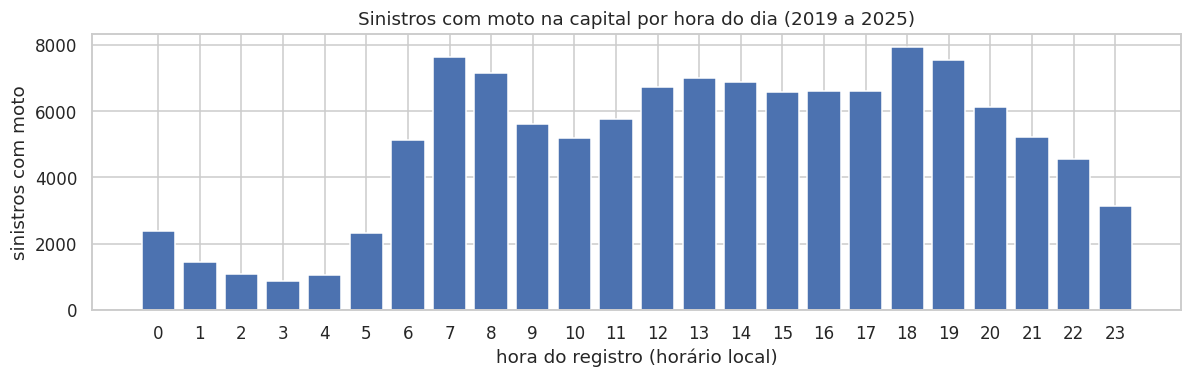

In [10]:
# Hora do sinistro: horas vazias e acúmulo suspeito à meia-noite

FATOR_SUSPEITA_MEIA_NOITE = 3.0       # regra prévia: "00:00" é tratado como hora desconhecida se tiver
                                      # mais de 3 vezes a média das horas cheias vizinhas (23:00 e 01:00)

hm = moto["hora_sinistro"].str.extract(r"^\s*(\d{1,2}):(\d{2})")
moto["hora"] = pd.to_numeric(hm[0], errors="coerce").astype("Int64")
moto["minuto"] = pd.to_numeric(hm[1], errors="coerce").astype("Int64")
moto.loc[~moto["hora"].between(0, 23).fillna(False), "hora"] = pd.NA

sem_hora = moto["hora"].isna()
n_0000 = int(((moto["hora"] == 0) & (moto["minuto"] == 0)).sum())
n_2300 = int(((moto["hora"] == 23) & (moto["minuto"] == 0)).sum())
n_0100 = int(((moto["hora"] == 1) & (moto["minuto"] == 0)).sum())
razao = n_0000 / max(1, (n_2300 + n_0100) / 2)
pct_minuto_zero = (moto.loc[~sem_hora, "minuto"] == 0).mean()

print("=" * 70)
print("HORA DO SINISTRO (sinistros com moto na capital)")
print("=" * 70)
print(f"Sem hora válida: {sem_hora.sum():,} ({sem_hora.mean():.2%})")
print(f"Entre os com vítima grave ou fatal: {moto.loc[moto['tem_grave_fatal'], 'hora'].isna().mean():.2%} sem hora")
print(f"Registros às 00:00: {n_0000:,} | às 23:00: {n_2300:,} | às 01:00: {n_0100:,} | razão: {razao:.2f}")
print(f"Registros em hora cheia (minuto 00), em qualquer hora: {pct_minuto_zero:.1%} (sem arredondamento seria ~1,7%)")
MEIA_NOITE_SUSPEITA = razao > FATOR_SUSPEITA_MEIA_NOITE
print(f"\n'00:00' tratado como hora desconhecida? {'SIM' if MEIA_NOITE_SUSPEITA else 'NÃO'} "
      f"(regra: razão > {FATOR_SUSPEITA_MEIA_NOITE})")

# Distribuição por hora: o perfil do dia antes de qualquer modelo
dist_hora = moto[~sem_hora].groupby("hora").size()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(dist_hora.index, dist_hora.values, color="#4C72B0")
ax.set_xticks(range(24))
ax.set_xlabel("hora do registro (horário local)")
ax.set_ylabel("sinistros com moto")
ax.set_title("Sinistros com moto na capital por hora do dia (2019 a 2025)")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item2_sinistros_por_hora.png", dpi=150, bbox_inches="tight")
plt.show()

### **2.5 Decisão da variável-alvo e tabela de eventos**

A célula aplica as regras definidas no início do item, sem ajuste manual:

1. escolhe o alvo A ou B conforme a porcentagem medida em 2.2 e o limiar de 80%;
2. exclui os sinistros sem hora utilizável (e o "00:00", se a regra de 2.4 o marcou como suspeito);
3. cria a `datahora_local`, a hora cheia do sinistro no horário de Brasília, que é a chave de junção com a grade de horas do Item 4;
4. salva a tabela de eventos em `dados/processados/eventos_alvo.parquet`. Ela guarda também logradouro e coordenadas, que o Item 10 usa para os trechos críticos.

In [15]:
# Decisão da variável-alvo e tabela de eventos para a base horária

# Regra do protocolo, aplicada aos números medidos em 2.2
ALVO = "A" if pct_vitima_na_moto >= LIMIAR_VITIMA_NA_MOTO else "B"
DESCRICAO_ALVO = {
    "A": "sinistros com pelo menos uma motocicleta e pelo menos uma vítima com lesão grave ou fatal",
    "B": "sinistros com pelo menos uma vítima com lesão grave ou fatal que estava em motocicleta",
}[ALVO]

if ALVO == "A":
    ids_alvo = moto.loc[moto["tem_grave_fatal"], "id_sinistro"]
else:
    ids_alvo = pd.Series(ids_b)

eventos = sinistros[sinistros["id_sinistro"].isin(ids_alvo)].copy()
hm = eventos["hora_sinistro"].str.extract(r"^\s*(\d{1,2}):(\d{2})")
eventos["hora"] = pd.to_numeric(hm[0], errors="coerce").astype("Int64")
eventos["minuto"] = pd.to_numeric(hm[1], errors="coerce").astype("Int64")
eventos.loc[~eventos["hora"].between(0, 23).fillna(False), "hora"] = pd.NA
if MEIA_NOITE_SUSPEITA:
    eventos.loc[(eventos["hora"] == 0) & (eventos["minuto"] == 0), "hora"] = pd.NA

n_total = len(eventos)
eventos = eventos[eventos["hora"].notna()].copy()
n_sem_hora = n_total - len(eventos)

# Hora local cheia do sinistro: é a chave de junção com a grade de horas do Item 4
eventos["datahora_local"] = eventos["data_sinistro"] + pd.to_timedelta(eventos["hora"].astype(int), unit="h")
eventos = eventos[["id_sinistro", "datahora_local", "ano_sinistro", "tipo_registro", "logradouro",
                   "latitude", "longitude", "qtd_motocicleta", "qtd_gravidade_fatal", "qtd_gravidade_grave"]]

CACHE_EVENTOS = DIR_PROCESSADOS / "eventos_alvo.parquet"
eventos.to_parquet(CACHE_EVENTOS, index=False)

horas_periodo = len(pd.date_range(f"{ANO_INICIO}-01-01", f"{ANO_FIM}-12-31 23:00", freq="h"))
print("=" * 70)
print("VARIÁVEL-ALVO")
print("=" * 70)
print(f"Alvo escolhido pela regra: {ALVO} ({pct_vitima_na_moto:.1%} contra o limiar de {LIMIAR_VITIMA_NA_MOTO:.0%})")
print(f"Definição: {DESCRICAO_ALVO}")
print(f"Sinistros do alvo: {n_total:,} | sem hora utilizável (excluídos): {n_sem_hora:,} ({n_sem_hora / n_total:.2%})")
print(f"Eventos que entram na base horária: {len(eventos):,}")
print(f"Média no período: {len(eventos) / horas_periodo:.3f} sinistros graves por hora "
      f"({len(eventos) / (horas_periodo / 24):.1f} por dia)")
display(eventos.groupby("ano_sinistro").size().to_frame("sinistros graves com hora"))
print(f"Tabela salva em {CACHE_EVENTOS.name}")

VARIÁVEL-ALVO
Alvo escolhido pela regra: A (88.6% contra o limiar de 80%)
Definição: sinistros com pelo menos uma motocicleta e pelo menos uma vítima com lesão grave ou fatal
Sinistros do alvo: 13,117 | sem hora utilizável (excluídos): 89 (0.68%)
Eventos que entram na base horária: 13,028
Média no período: 0.212 sinistros graves por hora (5.1 por dia)


,sinistros graves com hora
ano_sinistro,
2019,1787
2020,1753
2021,1804
2022,1874
2023,1818
2024,1947
2025,2045


Tabela salva em eventos_alvo.parquet


### **Discussão do Item 2**

#### **As notificações não trazem veículos nem pessoas (2.1)**

Os 108.821 registros do tipo NOTIFICACAO, 35,5% da capital, têm a quantidade de motos 100% vazia e só 3,4% deles têm pessoas registradas. Isso confirma a hipótese do Item 1: as notificações nunca poderiam aparecer como "com moto". Considerando só os 197.571 sinistros com boletim de ocorrência (fatais e não fatais), **as motos estão em 61,1% dos sinistros da capital**, e não em 39,4%. A tabela também mostra que, nesses sinistros, `qtd_motocicleta` vazia significa zero motos: as porcentagens "com moto" e "vazia" somam 100% em cada tipo de registro.

#### **Gravidade estável ao longo dos anos (2.1)**

Entre os 120.621 sinistros com moto, 13.117 (10,9%) têm pelo menos uma vítima grave ou fatal, com variação pequena de ano a ano (de 10,1% a 11,7%). A gravidade "não disponível" fica entre 5,4% e 6,9% em quase todos os anos, com um pico de 10,8% em 2021, e os campos de gravidade totalmente vazios não passam de 0,6%. O salto dos sinistros fatais visto no Item 1 tem uma pista aqui: de 2021 para 2022, os sinistros com vítima fatal sobem de 340 para 467 (127 a mais), mas os com vítima grave ou fatal sobem só de 1.814 para 1.899 (85 a mais). Ou seja, os sinistros com vítima grave e sem morte diminuem, o que sugere que parte dos casos antes registrados como graves passou a ser registrada como fatal. Para o alvo, que soma graves e fatais, essa mudança quase não pesa, e a série cresce de forma gradual. É mais um motivo para não usar só os fatais como alvo.

#### **Quem é a vítima grave (2.2)**

A tabela de sinistros e a de pessoas concordam em 100% dos casos sobre o número de vítimas graves ou fatais, e 99,9% dos sinistros com moto têm pessoas registradas. **Em 88,6% dos sinistros do alvo A, a vítima grave ou fatal estava na moto**, acima do limiar de 80% definido antes de ver os dados. Por isso, a regra manteve o **alvo A**. Entre todas as vítimas graves ou fatais desses sinistros, 95,3% eram motociclistas e 3,8% eram pedestres. A proporção entre os dois alvos (B / A) fica entre 88,0% e 89,9% em todos os anos, então os dois teriam o mesmo comportamento no tempo. O alvo A também é o que responde à pergunta como ela foi feita ("sinistros graves envolvendo motocicletas").

#### **Os dados batem com fontes independentes (2.3)**

A quantidade de motos é igual nas tabelas de sinistros e de veículos em 100% dos casos. Em 2025, a tabela de pessoas tem **1.038 vítimas fatais na capital (divulgado: 1.034) e 477 motociclistas mortos (divulgado: 475)**. A diferença de 4 e 2 mortes é compatível com a atualização da base: um óbito em até 30 dias pode ser incluído depois da divulgação, e os dados usados aqui são de 19/10/2026. É uma validação forte de que o recorte (capital, período e motocicletas) está correto. Também mostra que pedestres (410) são o segundo grupo que mais morre no trânsito da cidade.

#### **A hora do sinistro é confiável (2.4)**

Só 89 sinistros com moto não têm hora (0,07%), e todos estão entre os graves (0,68% deles). Provavelmente são registros fatais montados a partir de outras fontes, sem o horário. Eles foram excluídos, o que subconta muito pouco o alvo. O horário 00:00 não tem acúmulo suspeito (90 registros, contra 110 às 23:00 e 56 às 01:00, razão 1,08, bem abaixo do limite de 3), então foi mantido. Há um leve arredondamento para a hora cheia (2,7% dos registros no minuto 00, contra 1,7% esperado), que não afeta um modelo que agrega por hora.

#### **O perfil do dia já aparece (gráfico de 2.4)**

Os sinistros com moto têm dois picos, às 7h e às 18h (perto de 7,6 mil e 7,9 mil no período), um patamar alto entre 12h e 17h e o mínimo às 3h (menos de mil). É o desenho dos horários de deslocamento e de entregas, compatível com a hipótese H1. O gráfico mostra todos os sinistros com moto. O Item 5 refaz a análise só com os graves, que podem ter outro perfil (por exemplo, mais peso à noite).

#### **A variável-alvo (2.5)**

Ficam **13.028 sinistros graves com moto com hora utilizável**, entre 1.753 (2020) e 2.045 (2025) por ano. Na média, são **0,212 por hora (5,1 por dia)**: a grande maioria das horas terá zero sinistros graves. Isso confirma duas escolhas do protocolo. O objetivo de Poisson foi feito para contagens raras. E o MAE sozinho engana, porque prever sempre zero já teria um erro baixo.

Um ponto fica registrado para o Item 9. A média de 2019 a 2024 é de cerca de 1.830 sinistros graves por ano, e 2025 teve 2.045 (11,7% a mais). Como o ano não entra no modelo, é esperado que ele preveja um pouco menos do que aconteceu em 2025. Esse viés de nível será medido e discutido.

#### **Conclusão do Item 2**

O alvo é a **quantidade de sinistros com pelo menos uma motocicleta e pelo menos uma vítima com lesão grave ou fatal, por hora local**. A definição segue o dicionário de dados, é estável ao longo dos anos, representa o risco do entregador (88,6% com a vítima na moto) e foi validada com os números oficiais de 2025. A tabela de eventos está salva para a construção da base horária, depois que o Item 3 preparar o INMET.